# Project 27: Analisis KPI produksi

Semua tabel dibaca dari `results/` (hasil mart dbt). Data simulasi buatan sendiri, 150 file Excel harian.

In [1]:
from pathlib import Path
import pandas as pd, numpy as np, matplotlib.pyplot as plt
ROOT = Path.cwd()
while not (ROOT / 'results').exists():
    ROOT = ROOT.parent
R = lambda f: pd.read_csv(next((ROOT / 'results' / d / f) for d in ('1-data-preparation', '2-analysis', '3-presentation', '4-automation') if (ROOT / 'results' / d / f).exists()))
pd.options.display.float_format = '{:.4f}'.format
plt.rcParams.update({'figure.figsize': (9, 3.6), 'axes.spines.top': False, 'axes.spines.right': False})
BLUE, GREY, ORANGE = '#1A73E8', '#9AA0A6', '#E8710A'

## KPI per stasiun (urut proses)

In [2]:
k = R('kpi_station.csv').sort_values('sequence'); k[['station_name', 'input_qty', 'ng_qty', 'fpy', 'ng_rate', 'rework_rate', 'scrap_rate']]

,station_name,input_qty,ng_qty,fpy,ng_rate,rework_rate,scrap_rate
5,Chip Mounting,419428.0000,2881.0000,0.9931,0.0069,0.0032,0.0040
2,LED Soldering,419736.0000,4068.0000,0.9903,0.0097,0.0044,0.0058
3,Driver Assembly,419657.0000,3401.0000,0.9919,0.0081,0.0036,0.0049
6,Housing Assembly,420155.0000,2846.0000,0.9932,0.0068,0.0030,0.0042
4,Potting,420410.0000,3065.0000,0.9927,0.0073,0.0034,0.0043
7,Wiring Check,419336.0000,2292.0000,0.9945,0.0055,0.0025,0.0032
0,Burn-in Test,420014.0000,15551.0000,0.9630,0.0370,0.0131,0.0256
1,Photometric Test,420076.0000,5671.0000,0.9865,0.0135,0.0056,0.0085
8,Final QC,420118.0000,1993.0000,0.9953,0.0047,0.0023,0.0027
9,Packing,420567.0000,1064.0000,0.9975,0.0025,0.0011,0.0015


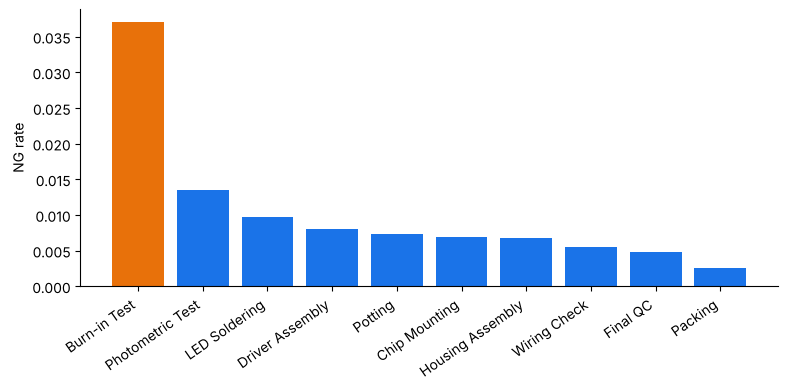

In [3]:
k2 = k.sort_values('ng_rate', ascending=False); plt.bar(k2.station_name, k2.ng_rate, color=[ORANGE] + [BLUE] * 9); plt.xticks(rotation=35, ha='right'); plt.ylabel('NG rate'); plt.show()

## KPI lini: RTY dan final yield

In [4]:
R('kpi_line_total.csv')

,rty,final_yield,rework_rate,n_days,n_rows,input_qty
0,0.9022,0.9368,0.0042,150,9000,4199497.0000


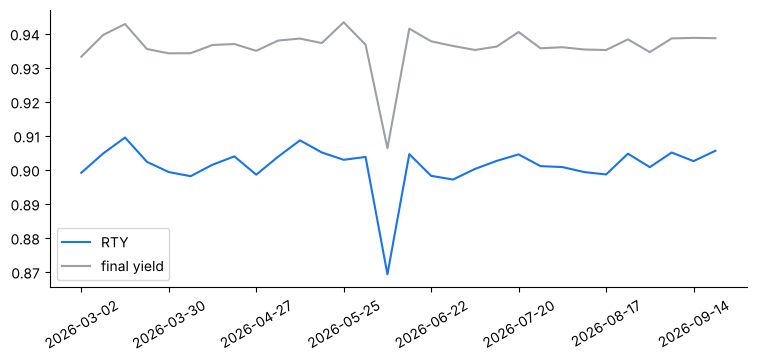

In [5]:
t = R('trend_weekly.csv'); plt.plot(t.week, t.rty, color=BLUE, label='RTY'); plt.plot(t.week, t.final_yield, color=GREY, label='final yield'); plt.xticks(t.week[::4], rotation=30); plt.legend(); plt.show()

## Minggu turun dan lonjakan harian

In [6]:
d = R('drop_weeks.csv'); display(d[d.is_drop]); s = R('spike_detection.csv'); s[s.is_spike]

,week,rty,final_yield,rework_rate,z_robust,is_drop,worst_station,worst_station_ng_rate,ng_rate_ratio
14,2026-06-08,0.8692,0.9063,0.0047,-9.6292,True,S08,0.0473,3.8863


,date,ng_qty,input_qty,ng_rate,z_robust,is_spike
70,2026-06-08,138.0000,2792.0000,0.0494,15.2725,True
71,2026-06-09,137.0000,2836.0000,0.0483,14.8125,True
72,2026-06-10,125.0000,2827.0000,0.0442,13.1313,True
73,2026-06-11,158.0000,2717.0000,0.0582,18.8582,True
74,2026-06-12,103.0000,2803.0000,0.0367,10.0616,True


## Pareto defect per stasiun
Defect dalam satu stasiun terbagi hampir merata, jadi tidak ada defect dominan.

In [7]:
R('pareto_80.csv')

,station_code,station_name,n_defect_types,n_types_to_80pct,top_defect,top_share,min_share,max_share
0,S01,Chip Mounting,2,2,CHP-01,0.5158,0.4842,0.5158
1,S02,LED Soldering,3,3,SLD-01,0.3456,0.3265,0.3456
2,S03,Driver Assembly,2,2,DRV-01,0.5054,0.4946,0.5054
3,S04,Housing Assembly,2,2,HSG-01,0.5063,0.4937,0.5063
4,S05,Potting,2,2,POT-01,0.5011,0.4989,0.5011
5,S06,Wiring Check,2,2,WIR-01,0.5009,0.4991,0.5009
6,S07,Burn-in Test,3,3,BRN-02,0.3391,0.3286,0.3391
7,S08,Photometric Test,3,3,PHM-01,0.3370,0.3264,0.3370
8,S09,Final QC,2,2,FQC-01,0.5088,0.4912,0.5088
9,S10,Packing,1,1,PKG-01,1.0000,1.0000,1.0000


## Shift dan model (chi-square)

In [8]:
display(R('ng_tests.csv')); R('ng_by_model.csv')

,factor,groups,chi2,dof,p_value,cramers_v,min_rate,max_rate,chi2_within_station,dof_within_station,p_within_station
0,shift,2,0.0915,1,0.7623,0.0001,0.0102,0.0102,3.8571,10,0.9536
1,model,3,446.9966,2,0.0000,0.0103,0.0091,0.0117,465.7876,20,0.0000


,model,input_qty,ng_qty,ng_rate
0,12W,1200162.0000,14061.0000,0.0117
1,5W,1558959.0000,14258.0000,0.0091
2,9W,1440376.0000,14513.0000,0.0101


## Validasi: mart vs rekap Excel (SUMIFS) dan rekap manual dari raw

In [9]:
b = R('crosscheck_excel.csv'); print(f'Excel vs mart: {(b.status == "PASS").sum()} dari {len(b)} PASS'); display(R('crosscheck_manual_causes.csv')); m = R('crosscheck_manual_diff.csv'); print('selisih FPY maks (poin):', round(m.fpy_diff_pts.abs().max(), 3))

Excel vs mart: 300 dari 300 PASS


,dirty_type,rows_in_sample,effect_on_manual_recap
0,blank_qty,9,NG kosong dihitung 0: NG dan NG rate terlalu r...
1,duplicate_row,8,"baris ganda terhitung dua kali di input, OK, d..."
2,lowercase_station,9,tidak berpengaruh (SUMIFS tidak membedakan hur...
3,negative_qty,9,NG negatif mengurangi total NG
4,text_qty,9,input bertulis teks diabaikan: input terlalu k...


selisih FPY maks (poin): 2.465


## Lima fakta yang ditanam dan hasil deteksi

In [10]:
display(R('event_detection.csv')); R('dirty_detection.csv')

,fact_no,fakta,penangkap,temuan,hasil
0,1,Burn-in Test paling sering NG,"analisis (fct_kpi_daily, Tabel KPI per stasiun)",Burn-in Test NG rate tertinggi: 3.70% (urutan ...,Sesuai
1,2,Lonjakan NG Photometric Test,analisis (anomali FPY stasiun per minggu),5 hari lonjakan 2026-06-08 s.d. 2026-06-12; mi...,Sesuai
2,3,Kolom file mentah berganti nama mulai bulan ke-4,test raw_schema_signature (hanya skema v1 dite...,"status fail: 60 file gagal, 60 file berubah",Sesuai
3,4,Satu file terlambat 2 hari,test raw_file_freshness (warn),1 file terlambat: produksi_20260520.xlsx,Sesuai
4,5,Data kotor,lima test raw_production_*,300 dari 300 baris kotor tertangkap (9060 bari...,Sesuai


,dirty_type,test,planted,detected,files_planted,files_detected,exact_per_file
0,blank_qty,raw_production_ng_blank,60,60,60,60,True
1,negative_qty,raw_production_ng_negative,60,60,60,60,True
2,text_qty,raw_production_qty_not_numeric,60,60,60,60,True
3,lowercase_station,raw_production_station_not_standard,60,60,60,60,True
4,duplicate_row,raw_production_duplicate,60,60,60,60,True


## Hasil uji dbt

In [11]:
t = R('dbt_test_results.csv'); t.groupby(['layer', 'status']).size()

layer    status
mart     pass      28
raw      pass       2
         warn       6
staging  pass      24
dtype: int64

## Dampak: waktu hemat dan angka naif vs bersih

In [12]:
display(R('impact_hours.csv')); display(R('impact_naive_vs_clean.csv')); R('impact_naive_by_station.csv')

,menit_per_laporan,laporan_per_tahun,jam_per_tahun,dasar
0,60,52,52.0000,asumsi (estimated)
1,90,52,78.0000,asumsi (estimated)
2,120,52,104.0000,asumsi (estimated)


,metrik,naif,bersih,keterangan
0,baris dipakai,5400.0000,9000.0000,raw 9060 baris; mart per hari x stasiun x mode...
1,input_qty total,2520782.0000,4199497.0000,NaN
2,NG total,25420.0000,42832.0000,NaN
3,NG rate,0.0101,0.0102,NaN
4,FPY,0.9897,0.9898,FPY = ok_first_pass / input


,station,fpy_naif,fpy_bersih,selisih
0,Burn-in Test,0.9628,0.9630,-0.0001
1,Chip Mounting,0.9931,0.9931,0.0000
2,Driver Assembly,0.9919,0.9919,-0.0000
3,Final QC,0.9952,0.9953,-0.0000
4,Housing Assembly,0.9932,0.9932,0.0000
5,LED Soldering,0.9903,0.9903,-0.0000
6,Packing,0.9975,0.9975,0.0001
7,Photometric Test,0.9859,0.9865,-0.0006
8,Potting,0.9926,0.9927,-0.0001
9,Wiring Check,0.9946,0.9945,0.0000


## Otomasi: log 10 run harian simulasi

In [13]:
display(R('run_log.csv')); R('gate_test.csv')

,run_date,jenis,file_baru,tes_pass,tes_warn,tes_error,model_sukses,gerbang
0,2026-09-14,full load awal,140,54,6,0,8,publish
1,2026-09-15,inkremental,1,54,6,0,8,publish
2,2026-09-16,inkremental,1,54,6,0,8,publish
3,2026-09-17,inkremental,1,54,6,0,8,publish
4,2026-09-18,inkremental,1,54,6,0,8,publish
5,2026-09-21,inkremental,1,54,6,0,8,publish
6,2026-09-22,inkremental,1,54,6,0,8,publish
7,2026-09-23,inkremental,1,54,6,0,8,publish
8,2026-09-24,inkremental,1,54,6,0,8,publish
9,2026-09-25,inkremental,1,54,6,0,8,publish


,skenario,uji_yang_gagal,tes_error,kode_keluar_gerbang,hasil
0,signature kolom file terakhir diubah menjadi t...,raw_schema_signature,1,1,tahan (tidak dipublikasikan)
